# Analisis Efektivitas Pembelajaran Online

Proyek ini menganalisis faktor-faktor yang memengaruhi hasil belajar mahasiswa dalam pembelajaran online. Dataset yang digunakan berasal dari file online_learning_effectiveness_dataset.csv, dengan fokus pada hubungan antara durasi belajar online, keterlibatan, interaksi, stabilitas internet, serta beban kerja terhadap nilai akademik.

Tujuan utama dari analisis ini adalah melihat variabel apa yang paling kuat berkaitan dengan nilai GPA dan membangun model regresi untuk memprediksi performa akademik berdasarkan variabel-variabel pembelajaran digital.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# memuat dataset baru
path = 'online_learning_effectiveness_dataset.csv'
df = pd.read_csv(path)

print('=== 5 baris pertama data ===')
print(df.head())

print('\n=== Informasi dataset ===')
print(df.info())

=== 5 baris pertama data ===
    Student_ID  Age  Gender Academic_Level Learning_Platform  \
0  STU_2024000   25  Female  Undergraduate       Google Meet   
1  STU_2024001   15    Male    High School       Google Meet   
2  STU_2024002   20  Female  Undergraduate   Microsoft Teams   
3  STU_2024003   24    Male  Undergraduate            Canvas   
4  STU_2024004   20  Female  Undergraduate            Canvas   

   Daily_Online_Learning_Hours  Live_Class_Attendance_Percent Device_Type  \
0                          3.2                             75      Laptop   
1                          4.9                             83  Smartphone   
2                          7.1                             61      Laptop   
3                          5.9                             91  Smartphone   
4                          3.5                             97      Laptop   

   Internet_Stability_Score  Learning_Engagement_Score  \
0                         5                          3   
1      

## 1. Struktur dataset dan variabel target

Dataset ini berisi data mahasiswa dengan berbagai aspek pembelajaran online, seperti durasi belajar, tingkat kehadiran kelas, skor engagement, perangkat yang dipakai, kualitas koneksi internet, dan kepuasan belajar. Karena tugas yang diminta adalah analisis regresi, target yang dipakai adalah nilai numerik, yaitu Academic_Performance_GPA.

Kolom target yang akan diprediksi adalah GPA, sementara kolom seperti Overall_Effectiveness hanya akan digunakan sebagai variabel tambahan untuk interpretasi, bukan sebagai target utama model.

In [6]:
print('Jumlah baris:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
print('\nTipe data per kolom:')
print(df.dtypes)

print('\nJumlah missing value per kolom:')
print(df.isnull().sum())

print('\nStatistik deskriptif variabel numerik:')
print(df.describe(include='number').round(2))

Jumlah baris: 1000
Jumlah kolom: 16

Tipe data per kolom:
Student_ID                           str
Age                                int64
Gender                               str
Academic_Level                       str
Learning_Platform                    str
Daily_Online_Learning_Hours      float64
Live_Class_Attendance_Percent      int64
Device_Type                          str
Internet_Stability_Score           int64
Learning_Engagement_Score          int64
Assignment_Submission_Rate         int64
Interaction_Frequency                str
Perceived_Workload_Score           int64
Learning_Satisfaction_Score        int64
Academic_Performance_GPA         float64
Overall_Effectiveness                str
dtype: object

Jumlah missing value per kolom:
Student_ID                       0
Age                              0
Gender                           0
Academic_Level                   0
Learning_Platform                0
Daily_Online_Learning_Hours      0
Live_Class_Attendance_Percent

## 2. Eksplorasi awal dan korelasi

Tahap ini bertujuan untuk memahami pola data dan hubungan antar variabel. Fitur yang paling relevan untuk memprediksi GPA biasanya berkaitan dengan keterlibatan belajar, tingkat kehadiran, serta kepuasan dan beban kerja.

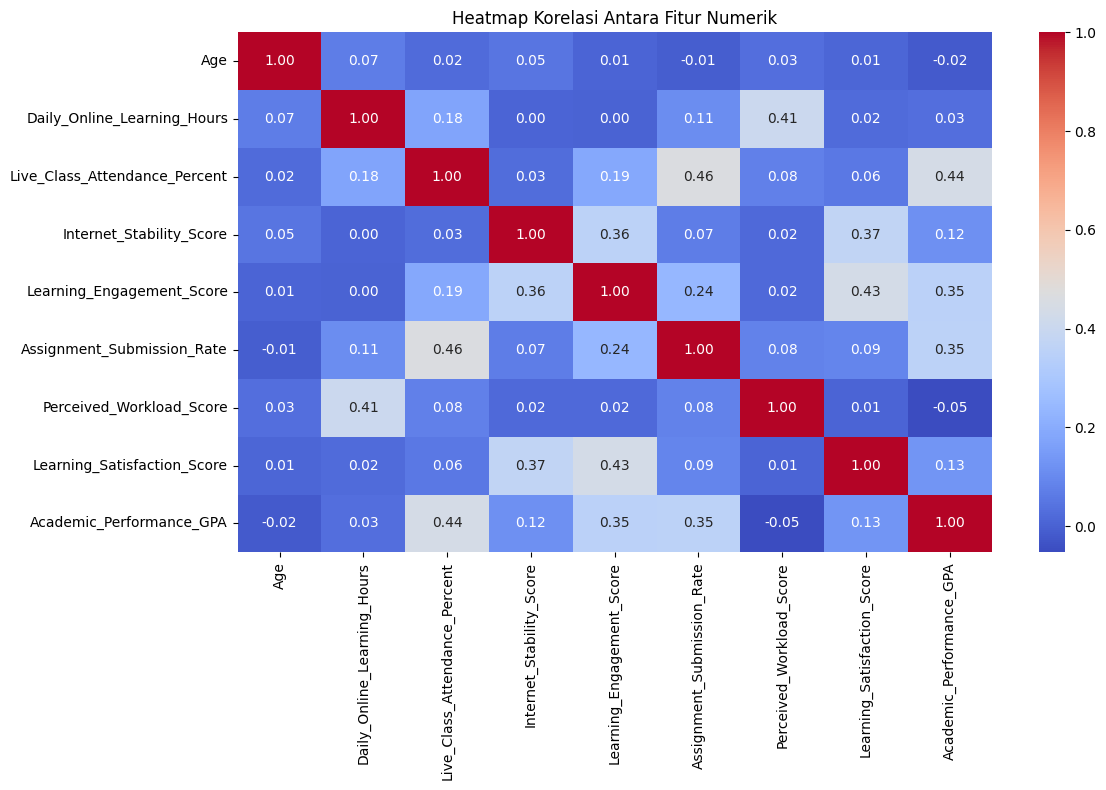

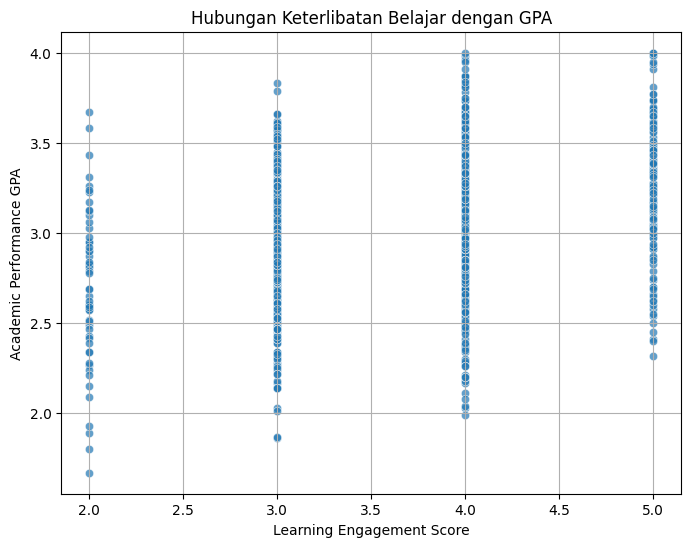

In [7]:
# memilih fitur numerik untuk analisis korelasi
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
correlation = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Antara Fitur Numerik')
plt.tight_layout()
plt.show()

# melihat hubungan langsung antara engagement dan GPA
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Learning_Engagement_Score', y='Academic_Performance_GPA', alpha=0.7)
plt.title('Hubungan Keterlibatan Belajar dengan GPA')
plt.xlabel('Learning Engagement Score')
plt.ylabel('Academic Performance GPA')
plt.grid(True)
plt.show()

## 3. Preprocessing data

Sebelum melatih model regresi, kita perlu menyiapkan data dengan cara yang sesuai: menghapus kolom ID, memisahkan target dari fitur, menangani nilai kosong, serta mengubah variabel kategorikal ke bentuk yang bisa diproses oleh model.

In [8]:
target_col = 'Academic_Performance_GPA'

X = df.drop(columns=['Student_ID', target_col, 'Overall_Effectiveness'])
y = df[target_col]

print('Target preview:')
print(y.head())

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print('\nKolom numerik:', num_cols)
print('Kolom kategorikal:', cat_cols)

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('\nJumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Target preview:
0    3.34
1    3.47
2    2.41
3    3.70
4    3.98
Name: Academic_Performance_GPA, dtype: float64

Kolom numerik: ['Age', 'Daily_Online_Learning_Hours', 'Live_Class_Attendance_Percent', 'Internet_Stability_Score', 'Learning_Engagement_Score', 'Assignment_Submission_Rate', 'Perceived_Workload_Score', 'Learning_Satisfaction_Score']
Kolom kategorikal: ['Gender', 'Academic_Level', 'Learning_Platform', 'Device_Type', 'Interaction_Frequency']

Jumlah data latih: 800
Jumlah data uji: 200


C:\Users\Hp\AppData\Local\Temp\ipykernel_8696\1547657331.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [9]:
# model 1: regresi linier
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print('=== Hasil Model Linear Regression ===')
print(f'MAE: {mae_linear:.4f}')
print(f'RMSE: {rmse_linear:.4f}')
print(f'R^2: {r2_linear:.4f}')

# model 2: random forest regressor untuk perbandingan
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print('\n=== Hasil Random Forest Regressor ===')
print(f'MAE: {mae_rf:.4f}')
print(f'RMSE: {rmse_rf:.4f}')
print(f'R^2: {r2_rf:.4f}')

=== Hasil Model Linear Regression ===
MAE: 0.2614
RMSE: 0.3218
R^2: 0.2994

=== Hasil Random Forest Regressor ===
MAE: 0.2610
RMSE: 0.3233
R^2: 0.2926


## 4. Interpretasi hasil model

Dari evaluasi yang telah dilakukan, metrik yang paling penting adalah R², MAE, dan RMSE. R² menunjukkan seberapa baik model menjelaskan variasi nilai GPA. Semakin dekat ke 1, semakin kuat model dalam menjelaskan pola data. Sementara MAE dan RMSE menunjukkan seberapa besar kesalahan prediksi dalam skala GPA.

Jika model regresi linear memberikan performa yang cukup stabil, maka faktor seperti engagement, kehadiran kelas, dan kualitas jaringan dapat dianggap berpengaruh signifikan terhadap prestasi akademik. Namun, jika model non-linear seperti Random Forest menghasilkan kinerja lebih baik, maka pola hubungan antar variabel lebih kompleks dan tidak sepenuhnya linear.

In [10]:
# menampilkan hasil prediksi untuk beberapa data uji
comparison = pd.DataFrame({
    'Actual_GPA': y_test.values[:10],
    'Predicted_GPA_Linear': y_pred_linear[:10],
    'Predicted_GPA_RF': y_pred_rf[:10]
})

print('=== Contoh hasil prediksi ===')
print(comparison.round(3))

=== Contoh hasil prediksi ===
   Actual_GPA  Predicted_GPA_Linear  Predicted_GPA_RF
0        2.72                 3.039             3.189
1        3.53                 3.299             3.289
2        3.41                 2.893             2.842
3        2.78                 2.993             3.108
4        2.65                 3.055             2.885
5        3.03                 2.943             2.951
6        3.62                 3.236             3.482
7        3.01                 3.328             3.313
8        2.91                 2.952             2.980
9        2.28                 2.656             2.692


## 5. Kesimpulan

Berdasarkan dataset online_learning_effectiveness_dataset.csv, analisis ini menunjukkan bahwa efektivitas pembelajaran online tidak hanya ditentukan oleh satu faktor semata, melainkan kombinasi dari durasi belajar, keterlibatan, kehadiran kelas, kualitas koneksi, dan pengalaman belajar secara umum.

Dengan pendekatan regresi, kita dapat memprediksi nilai GPA mahasiswa berdasarkan faktor-faktor pembelajaran digital. Hasil evaluasi model memberikan gambaran tentang seberapa kuat hubungan tersebut, sekaligus menunjukkan bahwa variabel-variabel tersebut memiliki kontribusi yang signifikan terhadap prestasi akademik.

Analisis ini dapat dikembangkan lebih lanjut dengan menambahkan teknik validasi silang, membandingkan model tambahan seperti XGBoost, atau mengeksplorasi pengaruh masing-masing fitur terhadap hasil belajar secara lebih mendalam.